In [2]:
from plantdata import load_classes, read_manifest
from pathlib import Path
from training import run_experiment
from plots import plot_history

SPLITS_DIR = Path("splits_v2")
CACHE_DIR = Path("cache_256")
CLASS_IDS, CROPS, crop_mask = load_classes(SPLITS_DIR)
manifest = read_manifest(CACHE_DIR)

SWEEP2 = [
    ("R11", "sgd",   3e-4, 1e-4, "LR sweep: SGD lr 3e-4 (below best)"),
    ("R12", "sgd",   1e-4, 1e-4, "LR sweep: SGD lr 1e-4 (below best)"),
    ("R13", "adamw", 3e-5, 0.01, "LR sweep: AdamW lr 3e-5 (below range)"),
]
for run_id, opt, lr, wd, note in SWEEP2:
    run_experiment(run_id, note, manifest, CACHE_DIR, CLASS_IDS, CROPS, crop_mask,
                   depth=18, freeze="none", augment=True, optimiser=opt, lr=lr, weight_decay=wd,
                   batch_size=64, epochs=15, patience=5, seed=42)

R11: LR sweep: SGD lr 3e-4 (below best) | 11,186,772 trainable weights
  epoch  1 | lr 3.00e-04 | train loss 0.847 acc 0.709 | val_lab F1-16 0.660 | val_wild F1-16 0.361 * | 252 s
  epoch  2 | lr 2.97e-04 | train loss 0.407 acc 0.880 | val_lab F1-16 0.857 | val_wild F1-16 0.430 * | 166 s
  epoch  3 | lr 2.87e-04 | train loss 0.267 acc 0.925 | val_lab F1-16 0.901 | val_wild F1-16 0.445 * | 32 s
  epoch  4 | lr 2.71e-04 | train loss 0.201 acc 0.944 | val_lab F1-16 0.918 | val_wild F1-16 0.450 * | 33 s
  epoch  5 | lr 2.50e-04 | train loss 0.161 acc 0.956 | val_lab F1-16 0.931 | val_wild F1-16 0.462 * | 118 s
  epoch  6 | lr 2.25e-04 | train loss 0.141 acc 0.960 | val_lab F1-16 0.940 | val_wild F1-16 0.466 * | 162 s
  epoch  7 | lr 1.96e-04 | train loss 0.123 acc 0.965 | val_lab F1-16 0.943 | val_wild F1-16 0.465 | 171 s
  epoch  8 | lr 1.66e-04 | train loss 0.118 acc 0.966 | val_lab F1-16 0.949 | val_wild F1-16 0.467 * | 183 s
  epoch  9 | lr 1.34e-04 | train loss 0.111 acc 0.968 | val_l

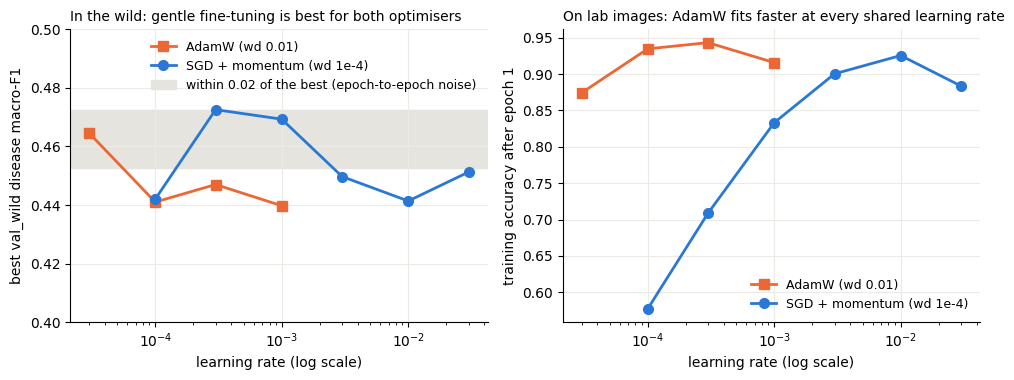

,run_id,optimiser,lr,val_wild_best,train_acc_epoch1
9,R13,adamw,0.0000,0.4646,0.8742
4,R08,adamw,0.0001,0.4410,0.9347
5,R09,adamw,0.0003,0.4470,0.9433
6,R10,adamw,0.0010,0.4397,0.9159
8,R12,sgd,0.0001,0.4420,0.5774
7,R11,sgd,0.0003,0.4726,0.7089
1,R05,sgd,0.0010,0.4693,0.8332
2,R06,sgd,0.0030,0.4497,0.9004
0,R04,sgd,0.0100,0.4414,0.9256
3,R07,sgd,0.0300,0.4513,0.8836


In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import json
SWEEP_IDS = ["R04", "R05", "R06", "R07", "R08", "R09", "R10", "R11", "R12", "R13"]   # all: R18, full fine-tune, aug, bs 64, seed 42

rows = []
for run_id in SWEEP_IDS:
    cfg = json.loads((Path("results/runs") / run_id / "config.json").read_text())
    h = pd.read_csv(Path("results/runs") / run_id / "history.csv")
    rows.append({"run_id": run_id, "optimiser": cfg["optimiser"], "lr": cfg["lr"],
                 "val_wild_best": h["val_wild_macro_f1_16_disease"].max(),
                 "train_acc_epoch1": h["train_acc"].iloc[0]})
sweep = pd.DataFrame(rows).sort_values(["optimiser", "lr"])

STYLE = {"sgd": ("#2a78d6", "o", "SGD + momentum (wd 1e-4)"), "adamw": ("#eb6834", "s", "AdamW (wd 0.01)")}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.9))
for opt, g in sweep.groupby("optimiser"):
    colour, marker, label = STYLE[opt]
    ax1.plot(g["lr"], g["val_wild_best"], color=colour, marker=marker, ms=7, lw=2, label=label)
    ax2.plot(g["lr"], g["train_acc_epoch1"], color=colour, marker=marker, ms=7, lw=2, label=label)
best = sweep.loc[sweep["val_wild_best"].idxmax()]
ax1.axhspan(best["val_wild_best"] - 0.02, best["val_wild_best"], color="#e5e4df", zorder=0,
            label="within 0.02 of the best (epoch-to-epoch noise)")
ax1.set_ylim(0.40, 0.50)
ax1.set_ylabel("best val_wild disease macro-F1")
ax1.set_title("In the wild: gentle fine-tuning is best for both optimisers", fontsize=10, loc="left")
ax2.set_ylabel("training accuracy after epoch 1")
ax2.set_title("On lab images: AdamW fits faster at every shared learning rate", fontsize=10, loc="left")
for ax in (ax1, ax2):
    ax.set_xscale("log")
    ax.set_xlabel("learning rate (log scale)")
    ax.grid(color="#ebeae5", lw=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.legend(frameon=False, fontsize=9, loc="upper right" if ax is ax1 else "lower right")
fig.tight_layout()
fig.savefig("figures/q3b_lr_optimiser.png", dpi=200)
plt.show()
sweep.round(4)